## 6.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import networkx as nx
import random
import sys

sys.path.append("../p4")
from fat_tails import mle_alpha, find_x_min

### 6.0.1 BA algorithm

In [ ]:
def ba_algorithm(new_edges, max_nodes, init_nodes):
    if new_edges > init_nodes:
        raise ValueError()

    matrix = np.zeros(shape=(max_nodes, max_nodes), dtype=int)
    matrix[:init_nodes, :init_nodes] = 1
    current_nodes = []
    for i in range(init_nodes):
        matrix[i, i] = 0
        current_nodes.extend([i] * (init_nodes - 1))

    for i in range(init_nodes, max_nodes):
        rnd_nodes = set()
        while len(rnd_nodes) < new_edges:
            rnd_nodes.add(random.choice(current_nodes))
        for node in rnd_nodes:
            matrix[i, node] = 1
            matrix[node, i] = 1
            current_nodes.append(node)
            current_nodes.append(i)
    return matrix

In [99]:
new_edges = 2
max_nodes = 10
init_nodes = 3
matrix = ba_algorithm(new_edges, max_nodes, init_nodes)
print(matrix)

[[0 1 1 1 1 1 0 0 0 1]
 [1 0 1 0 0 0 1 0 0 0]
 [1 1 0 1 1 0 0 1 1 1]
 [1 0 1 0 0 1 0 0 1 0]
 [1 0 1 0 0 0 1 0 0 0]
 [1 0 0 1 0 0 0 0 0 0]
 [0 1 0 0 1 0 0 1 0 0]
 [0 0 1 0 0 0 1 0 0 0]
 [0 0 1 1 0 0 0 0 0 0]
 [1 0 1 0 0 0 0 0 0 0]]


### 6.0.2 Animation

In [ ]:
new_edges = 1
max_nodes = 20
init_nodes = 3
matrix = ba_algorithm(new_edges, max_nodes, init_nodes)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

G_full = nx.from_numpy_array(matrix)
pos = nx.spring_layout(G_full, seed=123)

def update(i):
    ax.clear()

    G_tmp = nx.from_numpy_array(matrix[:i, :i])
    if i == init_nodes:
        node_colors = ["pink"] * i
    else:
        node_colors = ["pink"] * (i - 1) + ["deeppink"]

    nx.draw(
        G_tmp,
        pos,
        ax=ax,
        node_color=node_colors,
        edge_color="lightgray",
    )
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_title(f"t = {i-3}")
    ax.axis("off")


ani = animation.FuncAnimation(
    fig,
    update,
    frames=range(init_nodes, max_nodes + 1),
    interval=700,  # ms between frames
    repeat=False,
)

plt.close(fig)
HTML(ani.to_jshtml())

### 6.0.3 Plot the (averaged) histogram of the degree distribution at time t.

In [107]:
new_edges = 2
max_nodes = 1000
init_nodes = 10
n_runs = 50
times = [20, 100, 500, 1000]  # t = number of nodes in the graph

# hist_sum[j][k] = number of nodes with degree k at time times[j], summed over all runs
hist_sum = np.zeros(shape=(len(times), max_nodes))

for r in range(n_runs):
    matrix = ba_algorithm(new_edges, max_nodes, init_nodes)
    for j in range(len(times)):
        t = times[j]
        degrees = matrix[:t, :t].sum(axis=1)
        hist_sum[j] += np.bincount(degrees, minlength=max_nodes)

# averaged degree distribution P(k): divide by number of runs and number of nodes
p_k = np.zeros(shape=(len(times), max_nodes))
for j in range(len(times)):
    p_k[j] = hist_sum[j] / (n_runs * times[j])

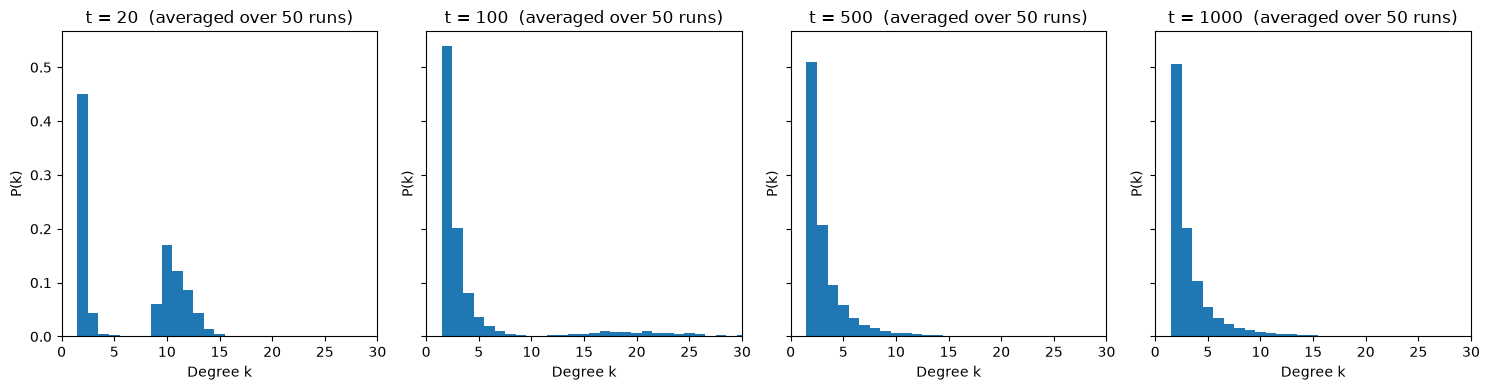

In [111]:
fig, axes = plt.subplots(1, len(times), figsize=(15, 4), sharey=True, sharex=True)
for j in range(len(times)):
    axes[j].bar(range(max_nodes), p_k[j], width=1)
    axes[j].set_xlim(0, 30)
    axes[j].set_xlabel("Degree k")
    axes[j].set_ylabel("P(k)")
    axes[j].set_title(f"t = {times[j]}  (averaged over {n_runs} runs)")
plt.tight_layout()
plt.show()

### 6.0.4 Find the $\alpha$ coefficient for the data from the previous tasks. Does it agree with our theoretical result from the lecture?

for the BA model $P(k) \sim k^{-3}$, so $\alpha = 3$

In [119]:
new_edges = 2
max_nodes = 1000
init_nodes = 10
n_runs = 50

alphas = []
for r in range(n_runs):
    matrix = ba_algorithm(new_edges, max_nodes, init_nodes)
    G = nx.from_numpy_array(matrix)
    x_min, D = find_x_min(G, list(range(2, 30)))
    alphas.append(mle_alpha(G, x_min))

print("mean alpha =", np.mean(alphas), "std =", np.std(alphas))

mean alpha = 3.094218458348611 std = 0.12920072462543683
